# Gated DeltaNet: a memory that can overwrite and forget

*Yang, Kautz, Hatamizadeh, "Gated Delta Networks: Improving Mamba2 with Delta Rule", ICLR 2025 ([arXiv 2412.06464](https://arxiv.org/abs/2412.06464)). Used in Qwen3-Next (36 Gated DeltaNet layers to 12 gated attention layers). Notebook 5 of 9 in the "How LLMs build on each other" series.*

**TL;DR.** Softmax attention keeps a cache that grows with the text. **Linear attention** replaces it with a fixed-size matrix $S$, a memory that every new token writes into and every query reads from. That makes cost per token constant, but plain linear attention can only *add* to the memory: it cannot correct a stored fact and it cannot clear space, so old content piles up and blurs. Two earlier fixes each repair one half. The **delta rule** (DeltaNet) turns the write into a *correction*: look up what the memory currently returns for this key, and replace it with the new value. **Gating** (Mamba-2) lets the memory fade by a data-dependent factor $\alpha_t$, so irrelevant content can be cleared in bulk. **Gated DeltaNet** does both:

$$ S_t = S_{t-1}\,\alpha_t\,(I-\beta_t k_t k_t^\top) + \beta_t v_t k_t^\top, \qquad o_t = S_t q_t . $$

In this notebook we derive the three rules one at a time, check each on a hand-built memory, run a small trained recall task that tests the paper's "delta rule remembers, gate clears" argument, and implement the paper's **chunkwise** algorithm, which is what makes it trainable on GPUs.

| step | what we do |
|---|---|
| 1 | linear attention is a recurrence over a matrix memory |
| 2 | the memory view: store key-value pairs, read them back; why plain addition fails |
| 3 | the delta rule as one step of gradient descent |
| 4 | gating, and the gated delta rule |
| 5 | trained recall tasks: linear vs decay vs delta vs gated delta (a standard task, then two tasks built to need each repair) |
| 6 | chunkwise parallel form: the same numbers with matmuls |
| 7 | the block, the hybrid, and the memory bill |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. Linear attention is a recurrence over a matrix

Softmax attention for one query: $o_t=\sum_{s\le t}\mathrm{softmax}_s(q_t\!\cdot\!k_s)\,v_s$. The softmax couples every key to every other (the denominator), which forces us to keep all keys. **Drop the softmax** and weight by the raw dot product instead:

$$ o_t = \sum_{s\le t} v_s\,(k_s^\top q_t) = \Big(\sum_{s\le t} v_s k_s^\top\Big) q_t = S_t\, q_t, \qquad S_t = S_{t-1} + v_t k_t^\top . $$

The sum of outer products $S_t\in\mathbb{R}^{d_v\times d_k}$ has a **fixed size** no matter how long the text is. To produce $o_t$ we need only $S_t$, not the history. That is a recurrence, an RNN whose state is a matrix. Two ways to compute the same thing:

In [2]:
torch.manual_seed(0)
T_, dk_, dv_ = 12, 6, 5
q, k, v = torch.randn(T_, dk_), torch.randn(T_, dk_), torch.randn(T_, dv_)
# (a) parallel form, like attention: (Q K^T masked causal) V, no softmax
par = ((q @ k.T) * torch.tril(torch.ones(T_, T_))) @ v
# (b) recurrent form: a fixed-size matrix state
rec, S = A.linear_attn_recurrent(q, k, v, rule="linear")
print("state size:", tuple(S.shape), "=", S.numel(), "numbers, whatever T is")
check("the parallel form and the recurrent form give the same outputs", torch.allclose(par, rec, atol=1e-5))

state size: (5, 6) = 30 numbers, whatever T is
PASS - the parallel form and the recurrent form give the same outputs 


## 2. The memory view, and why adding is not enough

Think of $S$ as a table that stores associations. If the keys were orthonormal, writing the pair $(k,v)$ with $S \mathrel{+}= v k^\top$ and reading with the same key, $Sk$, would return exactly $v$ (because $k_i^\top k_j=0$ for $i\ne j$ and $k_i^\top k_i=1$). Real keys are not orthogonal, and there are more tokens than dimensions, so reading returns the wanted value *plus a mix of everything else that was written*. Two failure modes, easy to see:

**(a) No correction.** Write $(k, v_1)$ and later $(k, v_2)$, the same key with a new value. A reader expects $v_2$. Linear attention returns $v_1+v_2$:

In [3]:
dk = 8
k0 = F.normalize(torch.randn(dk), dim=0)
v1, v2 = torch.randn(4), torch.randn(4)
keys = torch.stack([k0, k0]); vals = torch.stack([v1, v2])
_, S_lin = A.linear_attn_recurrent(keys, keys, vals, rule="linear")
read = S_lin @ k0
print("linear attention reads  v1+v2 :", np.allclose(read.numpy(), (v1 + v2).numpy(), atol=1e-5))
print("error against the NEW value v2 :", round((read - v2).norm().item(), 3))
check("linear attention returns the sum of old and new value for a repeated key", torch.allclose(read, v1 + v2, atol=1e-5))

linear attention reads  v1+v2 : True
error against the NEW value v2 : 1.744
PASS - linear attention returns the sum of old and new value for a repeated key 


**(b) No clean-up, too many items.** Store $n$ random pairs in a memory with $d_k$ key dimensions and read them all back. We measure the average relative error of the reads, for plain linear attention, as $n$ grows, for three memory sizes:

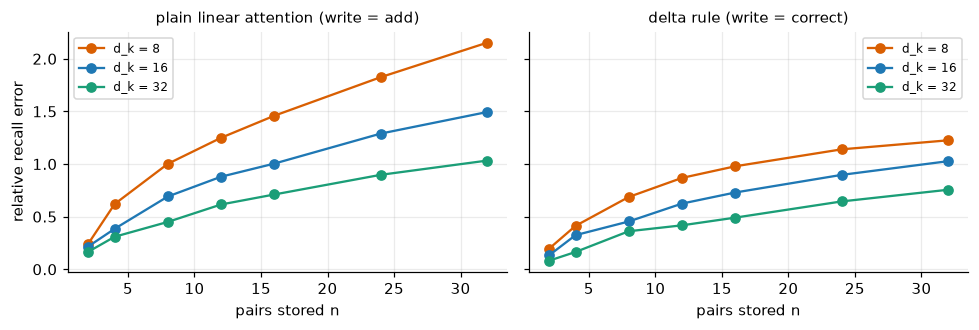

PASS - plain linear attention is not exact even at n = 2, because keys are not orthogonal 0.17
PASS - on average the delta rule recalls stored items better than plain addition (n = 8, d_k = 16) 


In [4]:
def recall_error(rule, n, dk, trials=30, beta=1.0):
    errs = []
    for _ in range(trials):
        kk = F.normalize(torch.randn(n, dk, dtype=torch.float64), dim=-1)
        vv = torch.randn(n, 8, dtype=torch.float64)
        b = torch.full((n,), beta, dtype=torch.float64)
        _, S = A.linear_attn_recurrent(kk, kk, vv, None, b, rule=rule)
        rd = kk @ S.T                                            # read every key
        errs.append(((rd - vv).norm(dim=-1) / vv.norm(dim=-1)).mean().item())
    return float(np.mean(errs))

ns = [2, 4, 8, 12, 16, 24, 32]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.1), sharey=True)
err = {}
for ax, rule, title in [(axs[0], "linear", "plain linear attention (write = add)"), (axs[1], "delta", "delta rule (write = correct)")]:
    for dkk, col in [(8, C["orange"]), (16, C["blue"]), (32, C["green"])]:
        e = [recall_error(rule, n, dkk) for n in ns]
        err[(rule, dkk)] = e
        ax.plot(ns, e, marker="o", label=f"d_k = {dkk}", color=col)
    ax.set_title(title, fontsize=10); ax.set_xlabel("pairs stored n"); ax.legend(fontsize=8)
axs[0].set_ylabel("relative recall error")
plt.tight_layout(); plt.show()
check("plain linear attention is not exact even at n = 2, because keys are not orthogonal", err[("linear", 32)][0] > 0.05, f"{err[('linear', 32)][0]:.2f}")
check("on average the delta rule recalls stored items better than plain addition (n = 8, d_k = 16)", err[("delta", 16)][2] < err[("linear", 16)][2])

## 3. The delta rule: write only what is missing

The fix is to make a write a **correction**. Before storing $(k, v)$, ask what the memory already returns for $k$, $v^{old}=Sk$, and store only the difference, scaled by a "writing strength" $\beta\in(0,1)$:

$$ S_t = S_{t-1} + \beta_t\,(v_t - S_{t-1}k_t)\,k_t^\top = S_{t-1}\big(I-\beta_t k_tk_t^\top\big)+\beta_t v_t k_t^\top . $$

For a unit-norm key and $\beta=1$ this **replaces** the stored value: afterwards $S_tk_t=v_t$ exactly. Expand $S_t k_t = S_{t-1}k_t - (S_{t-1}k_t)(k_t^\top k_t) + v_t(k_t^\top k_t) = v_t$. (With $\beta<1$ it moves a fraction of the way towards $v_t$.) The paper (their eq. 6 and the text after it) gives a second view that explains the name and the structure: this is **one step of stochastic gradient descent** on the loss $\tfrac12\|S k_t - v_t\|^2$, with learning rate $\beta_t$. The memory is a tiny linear model that is being trained online, token by token, to map keys to values. Both claims, checked:

In [5]:
dt = torch.float64
S0, kk, vv, b = torch.randn(5, 6, dtype=dt), F.normalize(torch.randn(6, dtype=dt), dim=0), torch.randn(5, dtype=dt), 0.37
# (1) the update equals one SGD step on 0.5 ||S k - v||^2
S_param = S0.clone().requires_grad_(True)
loss = 0.5 * ((S_param @ kk - vv) ** 2).sum()
loss.backward()
S_sgd = S0 - b * S_param.grad
S_rule = S0 - b * torch.outer(S0 @ kk, kk) + b * torch.outer(vv, kk)
check("the delta rule is exactly one SGD step on the key-to-value regression loss", torch.allclose(S_sgd, S_rule, atol=1e-12))
# (2) with beta = 1 and a unit key, the new value replaces the old one
S1 = S0 - torch.outer(S0 @ kk, kk) + torch.outer(vv, kk)
check("with beta = 1 and ||k|| = 1 the memory returns exactly the new value", torch.allclose(S1 @ kk, vv, atol=1e-12))

# overwrite demo: same key written twice
_, S_delta = A.linear_attn_recurrent(keys.to(dt), keys.to(dt), vals.to(dt), None, torch.ones(2, dtype=dt), "delta")
print("delta rule: error against the NEW value v2 =", round((S_delta @ k0.to(dt) - v2.to(dt)).norm().item(), 6), " (linear attention above:", round((S_lin @ k0 - v2).norm().item(), 3), ")")

PASS - the delta rule is exactly one SGD step on the key-to-value regression loss 
PASS - with beta = 1 and ||k|| = 1 the memory returns exactly the new value 
delta rule: error against the NEW value v2 = 0.0  (linear attention above: 1.744 )


The delta rule also **erases along the new key as a side effect**: the factor $(I-\beta kk^\top)$ shrinks every stored component that points along $k$. That is how it frees space, but only the part of memory aligned with the current key. It cannot clear the rest.

## 4. Gating: clearing the whole memory at once

Mamba-2 (and RetNet before it) multiply the memory by a decay $\alpha_t\in(0,1)$ before writing: $S_t=\alpha_tS_{t-1}+v_tk_t^\top$. If $\alpha_t$ is computed from the current token, the model can choose *when* to forget: near 1 to keep everything (carry on through a boilerplate stretch), near 0 to wipe the slate (a new document starts). The cost is that any information, useful or not, fades at the same rate. The paper's observation: **decay hurts retention, but filtering needs it**, while **the delta rule helps precise memorisation**. Each repairs what the other lacks, so combine them. Gated DeltaNet's update (paper eq. 10) applies the decay to the old memory *including* the erase step, and then writes:

$$ S_t = S_{t-1}\,\alpha_t\,(I-\beta_tk_tk_t^\top)+\beta_tv_tk_t^\top . $$

The four rules, side by side (this is exactly the kit's `linear_attn_recurrent`):

| rule | update | what it can do |
|---|---|---|
| linear attention | $S_t = S_{t-1} + v_tk_t^\top$ | add |
| Mamba-2 style decay | $S_t = \alpha_tS_{t-1} + v_tk_t^\top$ | add, forget everything a bit |
| DeltaNet | $S_t = S_{t-1}(I-\beta_tk_tk_t^\top)+\beta_tv_tk_t^\top$ | correct one key's value |
| **Gated DeltaNet** | $S_t = \alpha_t S_{t-1}(I-\beta_tk_tk_t^\top)+\beta_tv_tk_t^\top$ | correct, and clear |

Special cases to check: $\alpha=1$ gives DeltaNet, $\beta=0$ turns the update into pure decay with no write, and $\alpha=0$ wipes the memory before the write.

In [6]:
def linear_attn_recurrent(q, k, v, alpha=None, beta=None, rule="delta"):
    """One head, recurrent form.  q,k [T,dk]  v [T,dv]  alpha,beta [T]  ->  o [T,dv], S [dv,dk].
    rule = "linear"  : S_t = S_{t-1} + v k^T                                  (plain linear attention)
    rule = "decay"   : S_t = a S_{t-1} + v k^T                                (Mamba-2 style forget gate)
    rule = "delta"   : S_t = S_{t-1}(I - b k k^T) + b v k^T                   (DeltaNet)
    rule = "gdelta"  : S_t = S_{t-1} a (I - b k k^T) + b v k^T                (Gated DeltaNet, paper eq. 10)"""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dv, dk, dtype=q.dtype)
    o = []
    for t in range(T):
        kt, vt = k[t], v[t]
        a = alpha[t] if alpha is not None else 1.0
        b = beta[t] if beta is not None else 1.0
        if rule == "linear":
            S = S + torch.outer(vt, kt)
        elif rule == "decay":
            S = a * S + torch.outer(vt, kt)
        elif rule == "delta":
            S = S - b * torch.outer(S @ kt, kt) + b * torch.outer(vt, kt)
        elif rule == "gdelta":
            S = a * (S - b * torch.outer(S @ kt, kt)) + b * torch.outer(vt, kt)
        o.append(S @ q[t])
    return torch.stack(o), S


def gated_delta_chunkwise(q, k, v, alpha, beta, C=8):
    """Gated DeltaNet, chunkwise form (paper sec. 3.3): chunks are processed with matmuls and one small
    triangular solve instead of C sequential rank-1 updates.  Returns o [T,dv], final S [dv,dk]."""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dv, dk, dtype=q.dtype)
    outs = []
    for s0 in range(0, T, C):
        Q, Kc, V = q[s0:s0 + C], k[s0:s0 + C], v[s0:s0 + C]
        a, b = alpha[s0:s0 + C], beta[s0:s0 + C]
        n = Q.shape[0]
        g = torch.cumprod(a, 0)                                     # gamma_r: decay from chunk start to r
        Gam = g[:, None] / g[None, :]                               # Gamma_ij = gamma_i / gamma_j
        low = torch.tril(torch.ones(n, n, dtype=q.dtype))
        A = torch.tril(b[:, None] * (Gam * (Kc @ Kc.T)), -1)        # strictLower(diag(b) (Gamma o K K^T))
        Tm = torch.linalg.solve(torch.eye(n, dtype=q.dtype) + A, torch.diag(b))    # (I + A)^-1 diag(b)
        U = Tm @ V                                                  # "pseudo values" (decay already inside)
        Wm = Tm @ (g[:, None] * Kc)                                 # decayed "pseudo keys"
        Ucorr = U - Wm @ S.T                                        # what each token writes after removing what S already predicts
        o = (g[:, None] * Q) @ S.T + (Gam * (Q @ Kc.T) * low) @ Ucorr
        outs.append(o)
        S = g[-1] * S + Ucorr.T @ ((g[-1] / g)[:, None] * Kc)
    return torch.cat(outs), S


def kda_recurrent(q, k, v, alpha, beta):
    """Kimi Delta Attention (Kimi Linear paper eq. 1).  Same as the gated delta rule, but the decay
    alpha_t is a VECTOR over the key channels.  Layout follows the paper: S is [dk, dv].
        S_t = (I - b k k^T) Diag(alpha_t) S_{t-1} + b k v^T ;   o_t = S_t^T q_t"""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dk, dv, dtype=q.dtype)
    o = []
    for t in range(T):
        kt, vt, at, bt = k[t], v[t], alpha[t], beta[t]
        S = at[:, None] * S
        S = S - bt * torch.outer(kt, kt @ S) + bt * torch.outer(kt, vt)
        o.append(S.T @ q[t])
    return torch.stack(o), S


def kda_chunkwise(q, k, v, alpha, beta, C=8):
    """KDA, chunkwise (Kimi Linear sec. 3.1).  alpha [T,dk] per-channel decay.
    The trick that lets per-channel decay stay a matmul: fold the cumulative decay into q and k."""
    T, dk = k.shape
    dv = v.shape[1]
    S = torch.zeros(dk, dv, dtype=q.dtype)
    outs = []
    for s0 in range(0, T, C):
        Q, Kc, V = q[s0:s0 + C], k[s0:s0 + C], v[s0:s0 + C]
        a, b = alpha[s0:s0 + C], beta[s0:s0 + C]
        n = Q.shape[0]
        g = torch.cumprod(a, 0)                                     # [n,dk]: per-channel decay from chunk start
        Kd = g * Kc                                                 # k decayed forward to the chunk start frame
        Ki = Kc / g                                                 # k "undecayed" (used so ratios g_i/g_j appear)
        low = torch.tril(torch.ones(n, n, dtype=q.dtype))
        A = torch.tril(b[:, None] * (Kd @ Ki.T), -1)
        Tm = torch.linalg.solve(torch.eye(n, dtype=q.dtype) + A, torch.diag(b))
        W, U = Tm @ Kd, Tm @ V
        Ucorr = U - W @ S
        o = (g * Q) @ S + ((g * Q) @ Ki.T * low) @ Ucorr
        outs.append(o)
        S = g[-1][:, None] * S + (g[-1] / g * Kc).T @ Ucorr
    return torch.cat(outs), S

In [7]:
dt = torch.float64
T_, dk_, dv_ = 20, 6, 5
q = torch.randn(T_, dk_, dtype=dt); k = F.normalize(torch.randn(T_, dk_, dtype=dt), dim=-1); v = torch.randn(T_, dv_, dtype=dt)
ones, rnd = torch.ones(T_, dtype=dt), torch.rand(T_, dtype=dt)
o_g, S_g = A.linear_attn_recurrent(q, k, v, ones, rnd, "gdelta")
o_d, S_d = A.linear_attn_recurrent(q, k, v, None, rnd, "delta")
check("alpha = 1 gives DeltaNet", torch.allclose(S_g, S_d))
_, S_w = A.linear_attn_recurrent(q, k, v, torch.zeros(T_, dtype=dt), rnd, "gdelta")
check("alpha = 0 at the last step wipes the old memory: only the new write remains",
      torch.allclose(S_w, rnd[-1] * torch.outer(v[-1], k[-1])))

PASS - alpha = 1 gives DeltaNet 
PASS - alpha = 0 at the last step wipes the old memory: only the new write remains 


## 5. A trained test: multi-query associative recall

The paper argues from the single-needle-in-a-haystack benchmark (their Table 2, 1.3B models): with the full results at the longest lengths

| | S-NIAH-1 (8K) | S-NIAH-2 (4K) | S-NIAH-2 (8K) | S-NIAH-3 (4K) |
|---|---|---|---|---|
| DeltaNet | 98.8 | 18.6 | 14.4 | 22.4 |
| Mamba-2 | 30.4 | 56.2 | 17.0 | 4.6 |
| Gated DeltaNet | 91.8 | 92.2 | 29.6 | 27.6 |

DeltaNet keeps the repeated needle perfectly (decay does not erase it) but breaks on real text where memory fills up, and Mamba-2 does the opposite; Gated DeltaNet is good at both. We cannot train 1.3B models, but we can test the same logic on a small synthetic task, **multi-query associative recall (MQAR)**: the model reads $N$ key-value pairs (`k1 v1 k2 v2 ...`, keys and values being token ids), then reads the $N$ keys again in random order and has to output each key's value. Memory capacity is what limits it, so we vary $N$ at test time, up to more pairs than the memory has dimensions.

The model is one layer: embedding, then projections from the token and the previous token (a width-2 "short convolution", which is how a key-value pair gets bound together: at the value position, the layer sees both the value token and the key token before it), then one of the four recurrences, then an output layer. $d_k=d_v=16$ and one head, so the memory has 16 key dimensions. The gates are computed from the token: $\alpha_t=\sigma(w_\alpha\cdot x_t + 3)$ (starting near 1) and $\beta_t=\sigma(w_\beta\cdot x_t)$.

In [8]:
KV, VV, DM, DKV = 32, 32, 48, 16
NTOK = KV + VV

def mqar_batch(B, N, g):
    keys = torch.stack([torch.randperm(KV, generator=g)[:N] for _ in range(B)])             # distinct keys
    vals = torch.randint(0, VV, (B, N), generator=g) + KV
    pairs = torch.stack([keys, vals], -1).reshape(B, 2 * N)                                 # k1 v1 k2 v2 ...
    perm = torch.stack([torch.randperm(N, generator=g) for _ in range(B)])
    qk, ans = keys.gather(1, perm), vals.gather(1, perm) - KV
    return torch.cat([pairs, qk], 1), ans                                                   # inputs [B, 3N], answers [B, N]

class RecallNet(nn.Module):
    def __init__(self, rule):
        super().__init__()
        self.rule = rule
        self.emb = nn.Embedding(NTOK + 1, DM)           # +1: the RESET token used in section 5b
        self.q, self.k, self.v = (nn.Linear(2 * DM, DKV, bias=False) for _ in range(3))
        self.a, self.b = nn.Linear(2 * DM, 1), nn.Linear(2 * DM, 1)
        nn.init.constant_(self.a.bias, 3.0)
        self.out = nn.Linear(DKV, VV)

    def forward(self, tok):
        B, T = tok.shape
        x = self.emb(tok)
        x = torch.cat([x, F.pad(x, (0, 0, 1, 0))[:, :-1]], -1)                             # [token, previous token]
        q, k, v = F.normalize(self.q(x), dim=-1), F.normalize(self.k(x), dim=-1), self.v(x)
        alpha, beta = torch.sigmoid(self.a(x))[..., 0], torch.sigmoid(self.b(x))[..., 0]
        S = torch.zeros(B, DKV, DKV)
        o = []
        for t in range(T):
            kt, vt = k[:, t], v[:, t]
            if self.rule in ("decay", "gdelta"):
                S = alpha[:, t, None, None] * S
            if self.rule in ("delta", "gdelta"):
                S = S - beta[:, t, None, None] * (S @ kt[..., None]) * kt[:, None, :] + beta[:, t, None, None] * vt[..., None] * kt[:, None, :]
            else:
                S = S + vt[..., None] * kt[:, None, :]
            o.append((S @ q[:, t, :, None])[..., 0])
        return self.out(torch.stack(o, 1))

def train_recall(rule, seed, steps=1500, B=64):
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    net = RecallNet(rule)
    opt = torch.optim.Adam(net.parameters(), 3e-3)
    for s in range(steps):
        N = int(torch.tensor([4, 8, 12, 16])[torch.randint(0, 4, (1,), generator=g)])
        tok, ans = mqar_batch(B, N, g)
        logits = net(tok)[:, -N:]
        loss = F.cross_entropy(logits.reshape(-1, VV), ans.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
    return net

@torch.no_grad()
def recall_acc(net, N, n=400):
    tok, ans = mqar_batch(n, N, torch.Generator().manual_seed(1234))
    return (net(tok)[:, -N:].argmax(-1) == ans).float().mean().item()

rules = ["linear", "decay", "delta", "gdelta"]
Ns = [4, 8, 16, 24, 32]
acc = {}
t0 = time.time()
for r in rules:
    runs = []
    for s in [0, 1]:
        net = train_recall(r, s)
        runs.append([recall_acc(net, N) for N in Ns])
    acc[r] = np.array(runs)
    print(f"{r:7s} accuracy at N = {Ns}: {np.round(acc[r].mean(0), 2)}   ({time.time() - t0:.0f} s)")

linear  accuracy at N = [4, 8, 16, 24, 32]: [1.   1.   0.99 0.96 0.91]   (33 s)


decay   accuracy at N = [4, 8, 16, 24, 32]: [1.   1.   0.99 0.96 0.9 ]   (53 s)


delta   accuracy at N = [4, 8, 16, 24, 32]: [1.   1.   0.99 0.93 0.83]   (73 s)


gdelta  accuracy at N = [4, 8, 16, 24, 32]: [1.   1.   0.99 0.94 0.84]   (95 s)


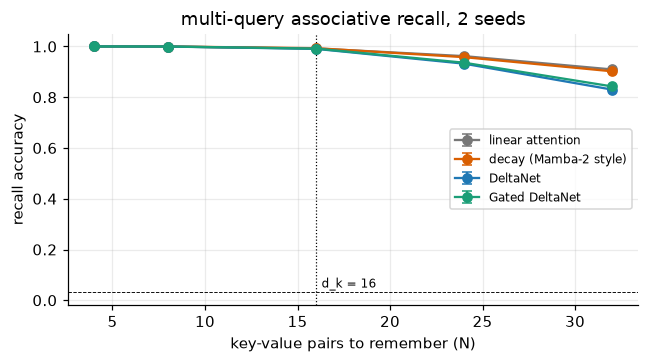

In [9]:
fig, ax = plt.subplots(figsize=(6.0, 3.4))
for r, c in zip(rules, [C["grey"], C["orange"], C["blue"], C["green"]]):
    m_, sd = acc[r].mean(0), acc[r].std(0)
    ax.errorbar(Ns, m_, sd, marker="o", color=c, capsize=3, label={"linear": "linear attention", "decay": "decay (Mamba-2 style)", "delta": "DeltaNet", "gdelta": "Gated DeltaNet"}[r])
ax.axvline(DKV, color="k", ls=":", lw=.8); ax.text(DKV + .3, .05, "d_k = 16", fontsize=8)
ax.axhline(1 / VV, color="k", ls="--", lw=.6); ax.set_xlabel("key-value pairs to remember (N)"); ax.set_ylabel("recall accuracy")
ax.set_title("multi-query associative recall, 2 seeds"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Result (2 seeds, accuracy; chance is 3%).** All four rules are essentially perfect up to 16 pairs (accuracy 0.99 to 1.00 at 4, 8 and 16 pairs), which is the memory's size. Beyond what was trained on (24 and 32 pairs; training used at most 16) accuracy falls, and **not in the order the paper predicts**: plain linear attention 0.96 and 0.91, decay 0.96 and 0.90, DeltaNet and Gated DeltaNet 0.93 and 0.83 (in the plot above). So on this standard task the delta rule and the gate give no advantage at our scale, and are slightly worse past capacity. The reason is probably that the layer can *learn* nearly orthogonal keys for 32 symbols in 16 dimensions, which removes the interference that the delta rule is there to fix; we did not test that explanation. This is a null result for the standard task, and the reason for the next two.

### 5b. Two tasks built to need each repair

The standard task above did not separate the four rules: with learned keys the layer can make the 16 stored keys nearly orthogonal and then plain addition is enough. So we build two tasks in which each repair is **needed by construction**, following the logic of the paper's case study.

**Overwrite task (needs the delta rule).** Eight distinct keys are written once each (in random order), then **eight more writes** hit random keys among the same eight, with new values. Then each of the eight keys is queried, and the right answer is the **latest** value written for that key. Plain addition returns the sum of all writes to a key; correction is exactly what this needs.

**Reset task (needs the gate).** A first "document" of 16 key-value pairs, then a special `RESET` token, then a second document of 16 pairs (its keys are drawn independently, so they may collide with the first document's), then queries for the 16 keys of the **second** document only. With a memory of 16 key dimensions, 32 stored items do not fit: without clearing the first document, its leftovers interfere. A gate that reads `RESET` and drops $\alpha$ to about 0 makes room. (The delta rule alone overwrites a key that appears again, but it only clears what it overwrites; a stale item whose key never reappears stays.)

In [10]:
RESET = NTOK
def overwrite_batch(B, g, nk=8, extra=8):
    keys0 = torch.stack([torch.randperm(KV, generator=g)[:nk] for _ in range(B)])                    # the 8 keys of each sample
    first = keys0.gather(1, torch.stack([torch.randperm(nk, generator=g) for _ in range(B)]))        # each written once
    upd = keys0.gather(1, torch.randint(0, nk, (B, extra), generator=g))                             # then 8 updates
    allk = torch.cat([first, upd], 1); L = allk.shape[1]
    vals = torch.randint(0, VV, (B, L), generator=g) + KV
    pairs = torch.stack([allk, vals], -1).reshape(B, 2 * L)
    match = allk[:, None, :] == keys0[:, :, None]                                                    # [B, nk, L]
    last = (match.float() * (torch.arange(L) + 1)).argmax(-1)                                        # index of the latest write
    ans = vals.gather(1, last) - KV
    qperm = torch.stack([torch.randperm(nk, generator=g) for _ in range(B)])
    return torch.cat([pairs, keys0.gather(1, qperm)], 1), ans.gather(1, qperm)

def reset_batch(B, g, N=16):
    def doc():
        k = torch.stack([torch.randperm(KV, generator=g)[:N] for _ in range(B)])
        v = torch.randint(0, VV, (B, N), generator=g) + KV
        return k, v, torch.stack([k, v], -1).reshape(B, 2 * N)
    kA, vA, pA = doc(); kB, vB, pB = doc()
    perm = torch.stack([torch.randperm(N, generator=g) for _ in range(B)])
    tok = torch.cat([pA, torch.full((B, 1), RESET), pB, kB.gather(1, perm)], 1)
    return tok, (vB - KV).gather(1, perm)

TASKS = {"overwrite": (overwrite_batch, 8), "reset": (reset_batch, 16)}

def train_task(rule, task, seed, steps=1000, B=64):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    batch, nq = TASKS[task]
    net = RecallNet(rule); opt = torch.optim.Adam(net.parameters(), 3e-3)
    for s in range(steps):
        tok, ans = batch(B, g)
        loss = F.cross_entropy(net(tok)[:, -nq:].reshape(-1, VV), ans.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
    tok, ans = batch(400, torch.Generator().manual_seed(4321))
    with torch.no_grad():
        return (net(tok)[:, -nq:].argmax(-1) == ans).float().mean().item(), net

task_acc = {}
t0 = time.time()
for task in ["overwrite", "reset"]:
    for r in rules:
        task_acc[(task, r)] = [train_task(r, task, s)[0] for s in [0, 1]]
        print(f"{task:9s} {r:7s} accuracy {np.round(task_acc[(task, r)], 3)}   ({time.time() - t0:.0f} s)")
print("chance 1/32 =", round(1 / 32, 3))
mean_acc = lambda t, r: float(np.mean(task_acc[(t, r)]))
check("overwrite task: plain addition fails, the delta rule solves it", mean_acc("overwrite", "linear") < 0.8 and mean_acc("overwrite", "delta") > 0.95)
check("overwrite task: decay alone is better than addition but well below the delta rule", mean_acc("overwrite", "linear") < mean_acc("overwrite", "decay") < mean_acc("overwrite", "delta") - 0.05)
check("reset task: plain addition fails, a gate solves it", mean_acc("reset", "linear") < 0.8 and mean_acc("reset", "decay") > 0.95)
check("Gated DeltaNet solves both tasks (accuracy above 0.95)", mean_acc("overwrite", "gdelta") > 0.95 and mean_acc("reset", "gdelta") > 0.95)

overwrite linear  accuracy [0.622 0.628]   (13 s)


overwrite decay   accuracy [0.866 0.863]   (27 s)


overwrite delta   accuracy [0.997 0.996]   (46 s)


overwrite gdelta  accuracy [0.998 0.998]   (66 s)


reset     linear  accuracy [0.719 0.718]   (109 s)


reset     decay   accuracy [0.994 0.993]   (178 s)


reset     delta   accuracy [0.973 0.969]   (269 s)


reset     gdelta  accuracy [0.992 0.994]   (364 s)
chance 1/32 = 0.031
PASS - overwrite task: plain addition fails, the delta rule solves it 
PASS - overwrite task: decay alone is better than addition but well below the delta rule 
PASS - reset task: plain addition fails, a gate solves it 
PASS - Gated DeltaNet solves both tasks (accuracy above 0.95) 


**Result (2 seeds; accuracy, chance is 3%).**

| rule | overwrite task | reset task |
|---|---|---|
| plain linear attention | 0.62 | 0.72 |
| decay only (Mamba-2 style) | 0.87 | 0.99 |
| delta rule only (DeltaNet) | 0.997 | 0.97 |
| Gated DeltaNet | 0.998 | 0.99 |

This is the pattern the paper argues for, and the first place in this notebook where the rules separate. On the **overwrite** task the delta rule is what matters: plain addition gets 0.62 (it returns old and new values summed), decay alone 0.87 (it can shade towards recent writes but not remove old ones), the two delta variants 0.997 to 0.998. On the **reset** task the gate is what matters: addition 0.72, but decay alone gets 0.99, because a gate that reads the `RESET` token can wipe the memory. The delta rule alone also does well (0.97): it overwrites whatever it needs, which clears a lot of space even without a gate, but it is a little behind (0.97 against 0.99). **Gated DeltaNet is at the top of both columns** (0.998 and 0.99), while decay is poor at one task and the delta rule slightly behind at the other; this is the complementarity of the paper's case study, in a layer small enough to read. Caveats: these tasks were designed by us to need each ingredient, so they show that the ingredients do what they should, not how much they matter in language; two seeds; and the gap between delta alone and Gated DeltaNet on the reset task (0.02) is small.

## 6. The chunkwise form: the same numbers, computed with matrix multiplications

The recurrence is sequential: step $t$ needs the state from step $t-1$, so a GPU cannot parallelise over time, and each step is a small, memory-bound operation. For training we want big matrix multiplications, which tensor cores are built for. The standard trick (used by linear attention, Mamba-2 and DeltaNet) is the **chunkwise** form: cut the sequence into chunks of size $C$; between chunks pass the state; inside a chunk, compute everything with matmuls. For plain linear attention this is easy (the paper's eq. 1): the output inside a chunk is the contribution of the state at the chunk start, plus a masked attention-like term $(QK^\top\odot M)V$ over the chunk.

The delta rule makes it harder, because each token's write depends on what the memory contained *including the writes made earlier in the same chunk*. The resolution (paper eq. 3 to 9, following Yang et al. 2024b) is a classical identity: a product of $r$ rank-one updates $(I-\beta_ik_ik_i^\top)$ can be rewritten compactly (the "WY representation"), and the coefficients needed come from solving one small **lower-triangular** $C\times C$ system. With $\gamma_r=\prod_{i\le r}\alpha_i$ the cumulative decay inside the chunk and $\Gamma_{ij}=\gamma_i/\gamma_j$:

1. $T=\big[I+\mathrm{strictLower}(\mathrm{diag}(\beta)\,(\Gamma\odot KK^\top))\big]^{-1}\mathrm{diag}(\beta)$, the triangular solve.
2. "Pseudo-values" $\tilde U = TV$ and decayed "pseudo-keys" $\tilde W = T\,(\gamma\odot K)$.
3. What each token really writes, after subtracting what the incoming state $S$ already predicts: $\tilde U - \tilde W S^\top$.
4. Outputs: $O=(\gamma\odot Q)S^\top + (QK^\top\odot\Gamma\odot M)(\tilde U-\tilde WS^\top)$.
5. Next state: $S \leftarrow \gamma_C S + (\tilde U-\tilde WS^\top)^\top\big(\tfrac{\gamma_C}{\gamma}\odot K\big)$.

This is the kit's `gated_delta_chunkwise`; it is written for one head and uses one `torch.linalg.solve` per chunk. The test of the algebra is simple: its output must equal the recurrence.

In [11]:
dt = torch.float64
T_, dk_, dv_ = 64, 8, 6
q = torch.randn(T_, dk_, dtype=dt)
k = F.normalize(torch.randn(T_, dk_, dtype=dt), dim=-1)
v = torch.randn(T_, dv_, dtype=dt)
alpha, beta = 0.6 + 0.4 * torch.rand(T_, dtype=dt), torch.rand(T_, dtype=dt)
o_rec, S_rec = A.linear_attn_recurrent(q, k, v, alpha, beta, "gdelta")
for C_ in [1, 4, 16, 64]:
    o_chk, S_chk = A.gated_delta_chunkwise(q, k, v, alpha, beta, C=C_)
    print(f"chunk size {C_:3d}: max |output difference| = {(o_rec - o_chk).abs().max().item():.1e}   sequential steps: {T_ // C_:3d} (of {T_})")
    check(f"chunkwise (C={C_}) equals the recurrence", torch.allclose(o_rec, o_chk, atol=1e-9) and torch.allclose(S_rec, S_chk, atol=1e-9))

chunk size   1: max |output difference| = 8.9e-16   sequential steps:  64 (of 64)
PASS - chunkwise (C=1) equals the recurrence 
chunk size   4: max |output difference| = 8.9e-16   sequential steps:  16 (of 64)
PASS - chunkwise (C=4) equals the recurrence 
chunk size  16: max |output difference| = 8.9e-16   sequential steps:   4 (of 64)
PASS - chunkwise (C=16) equals the recurrence 
chunk size  64: max |output difference| = 1.0e-15   sequential steps:   1 (of 64)
PASS - chunkwise (C=64) equals the recurrence 


With $C=64$ and $T=64$ the whole sequence is one chunk: one triangular solve and a few matmuls, no loop over time. $C=1$ is the plain recurrence. Real kernels pick $C$ around 64 and run the triangular solve and the matmuls in fast on-chip memory; that part cannot be shown on a CPU.

## 7. The block, the hybrid, and the memory bill

The paper's layer is a Llama-style block with attention replaced by the gated delta rule. $q$, $k$, $v$ come from linear projections followed by a short convolution and SiLU, with L2-normalisation on $q$ and $k$ (the stability trick we used above: with unit keys, $I-\beta kk^\top$ cannot amplify); $\alpha$ and $\beta$ are plain projections; the output goes through a normalisation and a gate before the output projection. The paper's Figure 1:

![The paper's Figure 1: the architecture and block design of Gated DeltaNet models. The Gated DeltaNet block replaces self-attention; hybrids (GatedDeltaNet-H1, -H2) interleave it with sliding-window attention and Mamba-2 layers.](../../assets/architecture_gallery/gdn_fig1_block.png)

**Why hybrids.** A fixed-size memory cannot retrieve everything exactly: its capacity is limited by $d_k$ (we saw it in section 5). So production models interleave a few softmax-attention layers, which give exact long-range lookup, with many linear layers: Qwen3-Next uses 36 Gated DeltaNet layers to 12 gated attention layers (the diagram's label), i.e. 3 to 1.

**The memory bill.** The state is $d_v\times d_k$ per head; a softmax layer's cache is $2\,G\,d_h$ numbers per token (notebook 1). For an *invented* layer with 16 heads of $d_k=d_v=128$ against a GQA layer with 8 key/value heads of width 128:

In [12]:
heads, dkk, dvv = 16, 128, 128
state = heads * dkk * dvv
per_tok = 2 * 8 * 128
print(f"Gated DeltaNet state per layer : {state:,} numbers, independent of length")
print(f"GQA-8 cache per layer          : {per_tok:,} numbers per token")
cross = state / per_tok
print(f"equal at {cross:.0f} tokens; at 32,768 tokens the cache is {per_tok * 32768 / state:.0f}x the state")
check("the linear layer's memory is smaller than the cache once the text is longer than state / per-token cache", per_tok * 32768 > state)

Gated DeltaNet state per layer : 262,144 numbers, independent of length
GQA-8 cache per layer          : 2,048 numbers per token
equal at 128 tokens; at 32,768 tokens the cache is 256x the state
PASS - the linear layer's memory is smaller than the cache once the text is longer than state / per-token cache 


## What this notebook did and did not show

**Shown (checks).** Linear attention equals a recurrence over a fixed-size matrix. Plain addition returns the sum of old and new values for a repeated key; the delta rule is exactly one SGD step and, with unit key and $\beta=1$, replaces the stored value exactly. The gated rule reduces to DeltaNet at $\alpha=1$ and wipes the memory at $\alpha=0$. The chunkwise algorithm reproduces the recurrence to $10^{-15}$ for chunk sizes from 1 to 64. Section 5 reports a trained comparison; its result and reading are written under it.

**Not shown.** The paper's results come from 1.3B models trained on 100B tokens, and the gains they report (language modelling, S-NIAH, throughput on H100) are not something a 16-dimension toy layer can test. Our recall task is synthetic, trained with 2 seeds, and it measures *memory use*, not language. We did not time anything on a GPU; the speed claim of the chunkwise form (their Figure 3) needs fused kernels. Mamba-2's exact parameterisation of $\alpha$ is simplified to a sigmoid of a linear projection.

**Next.** Notebook 6 changes one thing in the gate: Kimi Delta Attention makes the decay a **vector**, one rate per key channel, instead of one number per head.

In [13]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 17 | failed: 0
